# Gradient boosting

Gradient boosting cũng gộp nhiều cây, nhưng khác random forest: các cây được huấn luyện lần lượt, mỗi cây mới học phần sai mà các cây trước để lại, rồi cộng một phần nhỏ dự đoán của nó vào kết quả. Với loss bình phương, phần sai chính là hiệu giữa giá trị thật và dự đoán; với loss khác thì dùng gradient của loss, nên mới có chữ gradient trong tên. Với dữ liệu dạng bảng, đây thường là model mạnh nhất.

> **Mục tiêu**
>
> - Tính một bước boosting với loss bình phương.
> - So sánh boosting với random forest.
> - Chọn số cây và learning rate bằng validation.

## Ý tưởng: cộng dồn những bản vá

Mô hình cuối cùng là tổng của nhiều cây nhỏ:

$$F_M(\mathbf{x}) = F_0(\mathbf{x}) + \nu \sum_{m=1}^{M} h_m(\mathbf{x}),$$

trong đó $F_0$ là dự đoán ban đầu (ví dụ trung bình của $y$), mỗi $h_m$ là một cây nông, và $\nu \in (0, 1]$ là tốc độ học (learning rate, shrinkage).

Khác với random forest, các cây ở đây **không độc lập**: cây thứ $m$ được xây để sửa lỗi của $F_{m-1}$. Random forest giảm variance bằng cách trung bình nhiều cây sâu; boosting giảm bias bằng cách cộng dồn nhiều cây nông.



**Hỏi nhanh.** So random forest với gradient boosting khi ta thêm thật nhiều cây. Điểm trên validation của mỗi bên thường thay đổi thế nào?

- A. Cả hai đều tốt lên mãi, chỉ chậm dần
- B. Cả hai đều chắc chắn overfit nặng
- C. Rừng thì bão hòa, còn boosting có thể tệ đi
- D. Rừng thì tệ đi, còn boosting bão hòa

<details><summary>Đáp án</summary>

C. Rừng thì bão hòa, còn boosting có thể tệ đi

Rừng lấy trung bình các cây học độc lập, nên thêm cây chỉ làm trung bình ổn định hơn rồi đứng yên. Boosting thì cộng mãi các bản sửa. Sửa hết tín hiệu rồi, các cây sau quay sang sửa cả nhiễu. Vì vậy với boosting, ta phải chọn số vòng.

</details>

## Với sai số bình phương: học phần dư

Với loss $L = \frac12(y - F)^2$, ở bước $m$ ta tính phần dư $r_i = y_i - F_{m-1}(\mathbf{x}_i)$, huấn luyện cây $h_m$ để dự đoán $r_i$, rồi cập nhật $F_m = F_{m-1} + \nu h_m$. Lưu ý dấu: ở đây phần dư là **target trừ dự đoán**, tức hướng cần sửa, ngược với bài 2.1.

**Hỏi nhanh.** Một mẫu có target 10, dự đoán hiện tại là 6. Cây mới đoán phần dư của mẫu ấy là 3, vì lá của nó lấy trung bình nhiều mẫu. Với $\nu = 0.5$, sau bước này phần dư của mẫu còn bao nhiêu?

- A. 4
- B. 1
- C. 2.5
- D. 1.5

<details><summary>Đáp án</summary>

C. 2.5

Dự đoán mới là $6 + 0.5 \cdot 3 = 7.5$, nên phần dư mới là $10 - 7.5 = 2.5$. Cây không cần đoán đúng phần dư của từng mẫu, mỗi vòng chỉ cần đẩy đúng hướng một đoạn.

</details>



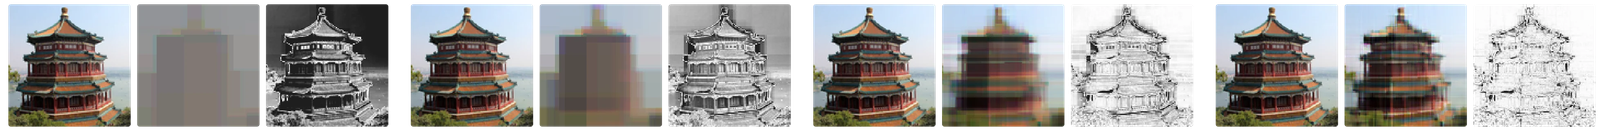

## Tổng quát: gradient descent trong không gian hàm

Phần dư $y - F$ chính là $-\dfrac{\partial L}{\partial F}$ với loss bình phương. Friedman (2001) nhận ra điều này đúng cho mọi loss khả vi: thay vì phần dư, ta khớp cây vào **gradient âm** (pseudo-residuals)

$$r_{im} = -\left.\frac{\partial L(y_i, F)}{\partial F}\right|_{F = F_{m-1}(\mathbf{x}_i)}.$$

Gradient descent ở bài 2.1 đi từng bước trong không gian tham số $\mathbf{w}$; gradient boosting đi từng bước trong không gian **hàm**, và mỗi bước là một cây. Đổi loss là đổi bài toán: log loss cho phân loại, Huber cho dữ liệu có outlier, các loss xếp hạng cho bài ranking.



**Hỏi nhanh.** Đổi loss từ bình phương sang trị tuyệt đối, $L = |y - F|$. Pseudo-residual của một mẫu là gì?

- A. $\operatorname{sign}(y - F)$, chỉ còn $\pm 1$
- B. $y - F$, giống hệt loss bình phương
- C. $(y - F)^2$, để phạt mạnh lỗi lớn
- D. $|y - F|$, độ lớn của lỗi

<details><summary>Đáp án</summary>

A. $\operatorname{sign}(y - F)$, chỉ còn $\pm 1$

$-\partial|y - F|/\partial F = \operatorname{sign}(y - F)$. Cây chỉ còn nghe được nên “nâng” hay “hạ”, không nghe được “bao nhiêu”. Vì vậy một điểm ngoại lai lệch 100 cũng chỉ có tiếng nói như một mẫu lệch 1, và loss trị tuyệt đối ít bị điểm ngoại lai kéo lệch.

</details>

## XGBoost: thêm đạo hàm bậc hai và regularization

XGBoost (Chen và Guestrin, 2016) khai triển Taylor bậc hai của loss quanh $F_{m-1}$. Với mỗi mẫu, gọi $g_i$ và $h_i$ là đạo hàm bậc một và bậc hai của loss theo dự đoán. Nếu một lá $j$ chứa tập mẫu $I_j$, đặt $G_j = \sum_{i\in I_j} g_i$ và $H_j = \sum_{i \in I_j} h_i$. Khi đó giá trị tối ưu của lá và lợi ích khi chia một lá thành hai là

$$w_j^\ast = -\frac{G_j}{H_j + \lambda},$$

$$\text{Gain} = \frac12\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma.$$

$\lambda$ là phạt L2 trên giá trị lá, $\gamma$ là “phí” cho mỗi lá mới: lại là “lỗi + phạt” của bài 2.2, lần này cài thẳng vào tiêu chí chia cây. Với loss bình phương, $g_i = F - y_i$ và $h_i = 1$, nên $w_j^\ast$ đúng là trung bình phần dư trong lá (co về 0 một chút nhờ $\lambda$).

**Hỏi nhanh.** Loss bình phương. Một lá chứa ba mẫu, với $g_i = F - y_i$ lần lượt là $-2$, $-1$, $-3$. Với $\lambda = 1$, giá trị lá $w^\ast$ bằng bao nhiêu?

- A. $2$
- B. $-1.5$
- C. $6$
- D. $1.5$

<details><summary>Đáp án</summary>

D. $1.5$

$G = -6$ và $H = 3$, vì mỗi mẫu có $h_i = 1$. Vậy $w^\ast = -G/(H + \lambda) = 6/4 = 1.5$. Không có $\lambda$ thì ra $2$, đúng bằng trung bình phần dư; $\lambda$ kéo giá trị lá về gần 0.

</details>

## Ba thư viện, ba điểm nhấn

| | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| Ý tưởng nổi bật | Đạo hàm bậc hai, regularization trong tiêu chí chia | Histogram, mọc cây theo lá (leaf-wise), rất nhanh | Xử lý cột phân loại bằng ordered target statistics |
| Tham số độ phức tạp | `max_depth` | `num_leaves` | `depth` (cây đối xứng) |
| Phù hợp khi | Cần ổn định, nhiều tài liệu | Dữ liệu lớn, cần tốc độ | Nhiều cột phân loại, ít muốn tinh chỉnh |

Cả ba đều xử lý giá trị thiếu sẵn và có bản chạy GPU. Trong scikit-learn, `HistGradientBoostingClassifier/Regressor` theo cùng tinh thần với LightGBM.

**Hỏi nhanh.** Bảng có 20 cột phân loại, nhiều cột có tới hàng nghìn giá trị như mã cửa hàng hay mã sản phẩm, và ta chỉ còn ít thời gian tinh chỉnh. Nên thử thư viện nào trước?

- A. XGBoost, sau khi one-hot mọi cột phân loại
- B. LightGBM, sau khi đổi mỗi mã thành một số nguyên
- C. CatBoost, đưa thẳng các cột phân loại vào
- D. Random forest, sau khi xóa các cột phân loại

<details><summary>Đáp án</summary>

C. CatBoost, đưa thẳng các cột phân loại vào

CatBoost mã hóa cột phân loại bằng thống kê target tính theo thứ tự, nên tránh được rò rỉ nhãn mà không làm số cột tăng vọt. One-hot hàng nghìn giá trị thì bảng rất thưa. Đổi mã thành số nguyên thì áp đặt một thứ tự vô nghĩa. Xóa cột thì mất thông tin.

</details>

## Ví dụ tính tay

Dữ liệu $x = (1, 2, 3, 4)$, $y = (1, 2, 6, 7)$, loss bình phương, $\nu = 0.5$, mỗi cây là một gốc cây (stump) chia một lần.

1. $F_0 = \bar y = 4$. Phần dư $r = (-3, -2, 2, 3)$. MSE $= 6.5$.
2. Stump tốt nhất cho $r$ chia giữa $x = 2$ và $x = 3$: lá trái dự đoán $-2.5$, lá phải $+2.5$.
3. $F_1 = 4 + 0.5 \cdot (-2.5, -2.5, 2.5, 2.5) = (2.75,\ 2.75,\ 5.25,\ 5.25)$. MSE $= 1.81$.

Phần dư mới $(-1.75, -0.75, 0.75, 1.75)$ nhỏ hơn hẳn, và cây thứ hai sẽ tiếp tục chia nhỏ chúng. Nếu chọn $\nu = 1$ thì một bước đã giảm nhiều hơn, nhưng trên dữ liệu thật, bước nhỏ cùng nhiều cây thường tổng quát tốt hơn.



## Tham số và cách chỉnh

- `learning_rate` và `n_estimators` đi đôi với nhau: tốc độ học nhỏ cần nhiều cây hơn. Cách làm chuẩn: cố định `learning_rate` khoảng 0.03–0.1, đặt số cây thật lớn, dùng **early stopping** trên validation để thư viện tự dừng khi điểm không tăng nữa.
- Độ phức tạp từng cây: `num_leaves` (15–127) hoặc `max_depth` (4–8), cùng `min_child_samples`.
- Ngẫu nhiên hóa để giảm overfit: lấy mẫu dòng (`subsample`, `bagging_fraction` khoảng 0.7–0.9) và cột (`colsample_bytree`, `feature_fraction` khoảng 0.7–0.9).
- Regularization: `reg_lambda`, `reg_alpha`.

Khác random forest, boosting **có thể overfit khi thêm cây**. Đó là lý do early stopping gần như bắt buộc.



**Hỏi nhanh.** Đang dùng `learning_rate=0.1`, early stopping dừng ở khoảng 300 cây. Đổi sang `learning_rate=0.01`, số cây trước khi dừng có xu hướng thế nào?

- A. Tăng nhiều, cỡ vài lần đến mười lần
- B. Giảm còn khoảng 30, vì mỗi cây mạnh hơn
- C. Không đổi, vì early stopping tự bù
- D. Không đoán được, vì hai tham số độc lập với nhau

<details><summary>Đáp án</summary>

A. Tăng nhiều, cỡ vài lần đến mười lần

Mỗi bản sửa nhỏ đi mười lần, nên cần nhiều bản sửa hơn để đi cùng một quãng đường. Thực tế thường cần cỡ vài lần đến mười lần số cây, và thời gian train cũng tăng tương ứng. Đổi lại, kết quả hay nhỉnh hơn một chút. Tỉ lệ chính xác thì phải đo mới biết.

</details>

## Một bản sửa nhìn được từng số

Cho bốn mẫu với target 1, 1, 3, 3. Mô hình ban đầu dự đoán trung bình là 2. Phần dư **target trừ dự đoán** là $-1, -1, 1, 1$: hai mẫu đầu cần hạ xuống, hai mẫu sau cần nâng lên. Trong bài 2.1 ta định nghĩa residual là dự đoán trừ target; ở đây đổi dấu để nó là hướng sửa. Đọc quy ước trước khi chép công thức tránh cập nhật ngược.

In [ ]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

xb = np.array([[0.], [1.], [2.], [3.]])
yb = np.array([1., 1., 3., 3.])
prediction = np.full(len(yb), yb.mean())
learning_rate = 0.5
for stage in range(3):
    residual_to_fix = yb - prediction
    correction = DecisionTreeRegressor(max_depth=1, random_state=0)
    correction.fit(xb, residual_to_fix)
    prediction = prediction + learning_rate * correction.predict(xb)
    mse_now = np.mean((prediction - yb) ** 2)
    print(stage + 1, prediction.tolist(), round(float(mse_now), 6))

1 [1.5, 1.5, 2.5, 2.5] 0.25
2 [1.25, 1.25, 2.75, 2.75] 0.0625
3 [1.125, 1.125, 2.875, 2.875] 0.015625


Lần đầu mô hình đi từ 2 về 1.5 hoặc 2.5. Phần còn thiếu chỉ bằng một nửa nên vòng sau dự đoán 1.25 hoặc 2.75. MSE giảm 1 → 0.25 → 0.0625 → 0.015625. Đây là dữ liệu hoàn hảo cho stump, không có nhiễu; thêm nhiều cây trên dữ liệu thật có thể tiếp tục giảm train loss nhưng làm validation xấu đi.



**Hỏi nhanh.** Target bằng 5, dự đoán hiện tại bằng 3, cây sửa đoán phần dư là 2. Với learning rate 0.1, dự đoán mới bằng bao nhiêu?

- A. 5
- B. 3.2
- C. 2.8
- D. 3.02

<details><summary>Đáp án</summary>

B. 3.2

Ta cộng thêm learning rate nhân bản sửa: $3 + 0.1 \cdot 2 = 3.2$. Ra 5 là quên learning rate. Ra 2.8 là trừ thay vì cộng. Learning rate nhỏ khiến mỗi bản sửa chỉ có tiếng nói nhỏ.

</details>

## Theo dõi validation theo số cây

Ta cần xem hai đường loss chứ không chỉ số cuối cùng. Với `GradientBoostingRegressor`, `staged_predict` trả dự đoán sau từng vòng, nên một lần fit cho cả đường cong và mô hình tốt có thể nằm trước vòng cuối. Thí nghiệm dưới dùng dữ liệu phi tuyến có nhiễu lớn và cây sâu 3, đủ để thấy boosting học thuộc.

In [ ]:
from sklearn.datasets import make_friedman1
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

X_stage, y_stage = make_friedman1(n_samples=250, noise=4.0, random_state=3)   # phi tuyến, nhiễu lớn
X_train, X_valid, y_train, y_valid = train_test_split(X_stage, y_stage, test_size=0.3, random_state=8)
boost = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=0)
boost.fit(X_train, y_train)
train_losses = [np.mean((pred - y_train) ** 2) for pred in boost.staged_predict(X_train)]
valid_losses = [np.mean((pred - y_valid) ** 2) for pred in boost.staged_predict(X_valid)]
best_round = int(np.argmin(valid_losses)) + 1
print("vòng chọn:", best_round)
print("MSE train, vòng chọn và vòng cuối:", round(float(train_losses[best_round - 1]), 2), round(float(train_losses[-1]), 2))
print("MSE valid, vòng chọn và vòng cuối:", round(float(valid_losses[best_round - 1]), 2), round(float(valid_losses[-1]), 2))

vòng chọn: 31
MSE train, vòng chọn và vòng cuối: 6.84 0.08
MSE valid, vòng chọn và vòng cuối: 20.86 23.05




Train MSE đi từ $6.84$ ở vòng 31 xuống $0.08$ ở vòng 300: mô hình gần như thuộc lòng 175 mẫu train. Validation thấp nhất ở vòng 31 ($20.86$), rồi tăng lên $23.05$: 269 cây cuối chủ yếu học nhiễu. Nếu cứ chạy hết 300 vòng, ta trả thêm thời gian để có mô hình tệ hơn khoảng 10%. Vì vòng 31 được chọn bằng chính tập validation này, con số $20.86$ hơi lạc quan; muốn ước lượng độc lập cần một test để riêng.

**Hỏi nhanh.** Trong thí nghiệm trên, MSE validation thấp nhất ở vòng 31 với 20.86, còn ở vòng 300 là 23.05. Nên lưu mô hình ở vòng nào, và báo điểm nào làm ước lượng cho dữ liệu mới?

- A. Vòng 300, báo MSE validation 23.05
- B. Vòng 300, báo MSE train 0.08
- C. Vòng 31, báo MSE train 6.84
- D. Vòng 31, báo điểm trên một tập test riêng

<details><summary>Đáp án</summary>

D. Vòng 31, báo điểm trên một tập test riêng

Vòng 31 thắng trên validation nên là mô hình cần giữ. Nhưng con số 20.86 đã được dùng để chọn vòng, nên hơi lạc quan. Điểm train thì càng không nói gì về dữ liệu mới. Ước lượng sạch phải đến từ dữ liệu chưa tham gia việc chọn.

</details>

## Dùng thư viện

In [ ]:
from sklearn.datasets import make_friedman1
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

X, y = make_friedman1(n_samples=5000, noise=1.0, random_state=0)   # quan hệ phi tuyến có tương tác
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=0)
model = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=2000, max_leaf_nodes=31,
                                      early_stopping=True, validation_fraction=0.1,
                                      n_iter_no_change=50, random_state=0)
model.fit(X_tr, y_tr)
print("số cây:", model.n_iter_, " R2 validation:", round(model.score(X_va, y_va), 3))

số cây: 285  R2 validation: 0.944


**Hỏi nhanh.** Đặt `max_iter=2000`, nhưng mô hình chỉ có `n_iter_ = 285` cây. Vì sao?

- A. Hết thời gian chạy nên thư viện tự dừng
- B. Learning rate tự giảm về 0 sau 285 vòng
- C. Từ vòng 286, các cây mới đều bằng 0
- D. Early stopping dừng sau 50 vòng liền không cải thiện

<details><summary>Đáp án</summary>

D. Early stopping dừng sau 50 vòng liền không cải thiện

`early_stopping=True` tách 10% train (`validation_fraction=0.1`) làm validation nội bộ, rồi dừng khi `n_iter_no_change=50` vòng liền không cải thiện. Phần validation nội bộ ấy được chia ngẫu nhiên theo hàng. Với dữ liệu có nhóm hay theo thời gian, ta phải tự làm validation đúng cấu trúc.

</details>

Với LightGBM, đoạn tương đương là `LGBMRegressor(learning_rate=0.05, n_estimators=5000, num_leaves=31)` kèm `callbacks=[lightgbm.early_stopping(100)]` khi `fit`.

## LightGBM trong khuôn K-fold

Đề bảng thường cho `train` có nhãn và `test` không nhãn. Chia train thành $K$ fold; mỗi fold học trên $K-1$ phần, phần còn lại dùng cho early stopping và để chấm. Mỗi dòng train được dự đoán đúng một lần bởi model **chưa thấy nó**; gom lại là dự đoán out-of-fold (OOF). Dự đoán cho test là trung bình $K$ model.

Dữ liệu dưới có tám cột số và cột `city` kiểu `category`; LightGBM nhận thẳng, không cần one-hot.

In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

X_num, y = make_classification(n_samples=3000, n_features=8, n_informative=5, flip_y=0.08, random_state=1)
rng = np.random.default_rng(1)
df = pd.DataFrame(X_num, columns=[f"f{i}" for i in range(8)])
df["city"] = rng.choice(["HN", "HCM", "DN", "HP", "CT"], size=len(df))
y = np.where(df["city"].isin(["HN", "DN"]) & (rng.random(len(df)) < 0.25), 1, y)   # thành phố có ảnh hưởng thật
df["city"] = df["city"].astype("category")
train, test = df.iloc[:2400], df.iloc[2400:]
y_train, y_test = y[:2400], y[2400:]

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
oof = np.zeros(len(train))
test_pred = np.zeros(len(test))
for k, (tr, va) in enumerate(folds.split(train, y_train)):
    model = lgb.LGBMClassifier(learning_rate=0.05, n_estimators=2000, num_leaves=15,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=0, verbose=-1, n_jobs=1)
    model.fit(train.iloc[tr], y_train[tr], eval_set=[(train.iloc[va], y_train[va])],
              eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
    oof[va] = model.predict_proba(train.iloc[va])[:, 1]
    test_pred += model.predict_proba(test)[:, 1] / folds.n_splits
    print(f"fold {k}: cây tốt nhất {model.best_iteration_}, AUC {roc_auc_score(y_train[va], oof[va]):.3f}")
print("AUC out-of-fold:", round(roc_auc_score(y_train, oof), 3))
print("AUC test (trung bình 5 model):", round(roc_auc_score(y_test, test_pred), 3))

fold 0: cây tốt nhất 104, AUC 0.929
fold 1: cây tốt nhất 98, AUC 0.898
fold 2: cây tốt nhất 79, AUC 0.920
fold 3: cây tốt nhất 74, AUC 0.905
fold 4: cây tốt nhất 89, AUC 0.934
AUC out-of-fold: 0.917
AUC test (trung bình 5 model): 0.923




Mỗi fold chọn số cây riêng (74 đến 104); `n_estimators=2000` chỉ là trần. AUC từng fold lệch nhau tới 0.036, nên một lần chia train/valid có thể sai cỡ ±0.02. Điểm OOF 0.917 gộp cả 2400 dòng và sát điểm test 0.923. Khi thử đặc trưng hay tham số mới, so điểm OOF, không so điểm một fold.

Sau early stopping, `predict_proba` tự dùng số cây tốt nhất. Mảng `oof` còn dùng để trộn model, vì không model nào đã thấy nhãn của dòng mình dự đoán.

**Hỏi nhanh.** Vì sao điểm trên `oof` ước lượng được điểm trên dữ liệu mới, còn điểm của model fold 0 chấm lại trên toàn bộ train thì không?

- A. `oof` có nhiều dòng hơn
- B. Mỗi dòng của `oof` được dự đoán bởi model chưa học dòng đó
- C. Model fold 0 dừng sớm hơn các fold khác
- D. `StratifiedKFold` giữ tỉ lệ nhãn

<details><summary>Đáp án</summary>

B. Mỗi dòng của `oof` được dự đoán bởi model chưa học dòng đó

Model fold 0 đã học 80% số dòng train, nên chấm lại trên toàn bộ train phần lớn là chấm bài nó đã thuộc. Mỗi dòng của `oof` được chấm bởi model không thấy nó, giống dữ liệu test.

</details>

Với XGBoost chỉ cần thay model; giữ nguyên `folds` để hai bộ OOF so được từng dòng:

In [ ]:
import xgboost as xgb

oof_xgb = np.zeros(len(train))
for k, (tr, va) in enumerate(folds.split(train, y_train)):
    model = xgb.XGBClassifier(learning_rate=0.05, n_estimators=2000, max_depth=4, subsample=0.8,
                              colsample_bytree=0.8, enable_categorical=True, tree_method="hist",
                              early_stopping_rounds=100, eval_metric="auc", random_state=0, n_jobs=1)
    model.fit(train.iloc[tr], y_train[tr], eval_set=[(train.iloc[va], y_train[va])], verbose=False)
    oof_xgb[va] = model.predict_proba(train.iloc[va])[:, 1]
print("AUC OOF XGBoost:", round(roc_auc_score(y_train, oof_xgb), 3))
print("AUC OOF trung bình hai thư viện:", round(roc_auc_score(y_train, (oof + oof_xgb) / 2), 3))

AUC OOF XGBoost: 0.918
AUC OOF trung bình hai thư viện: 0.919


Trung bình hai bộ OOF chỉ tăng 0.001: hai model cùng loại cây, cùng đặc trưng nên sai ở những dòng giống nhau. Trộn có lợi khi các model sai ở chỗ khác nhau (bài 8.4). Mức tăng nhỏ như vậy còn dưới độ dao động giữa các seed.

`enable_categorical=True` cho XGBoost đọc cột `category`, đi cùng `tree_method="hist"`. CatBoost nhận cột phân loại qua `cat_features`; máy chưa có thì `pip install catboost`.

## Khi đi thi

- **Mặc định cho dữ liệu bảng.** Một LightGBM hoặc CatBoost với tham số hợp lý và early stopping thường đã đứng đầu trong số các mô hình đơn lẻ.
- **Quy trình**: K-fold, trong mỗi fold huấn luyện có early stopping trên fold validation, lưu dự đoán out-of-fold để đánh giá và dự đoán test là trung bình của $K$ mô hình.
- **Điểm tăng nằm ở đặc trưng** (bài 2.11) nhiều hơn ở tinh chỉnh tham số. Chỉnh tham số kỹ thường thêm vài phần nghìn; một đặc trưng đúng có thể thêm vài phần trăm.
- **Trung bình nhiều seed** (3–5 seed khác nhau) là cách rẻ nhất để ổn định điểm.
- **GPU khi được cấp**: kiểm phiên bản và hướng dẫn backend của thư viện, đo thử trước. Code trong bài chạy CPU; không suy ra tốc độ GPU từ kết quả CPU.

## Tóm tắt

- Boosting cộng dồn các cây nông, mỗi cây khớp gradient âm của loss tại mô hình hiện tại.
- Random forest trung bình các cây sâu để giảm variance; boosting cộng các cây nông để giảm bias, nhưng thêm cây quá nhiều thì overfit. Chọn số vòng bằng validation đúng cấu trúc dữ liệu.
- XGBoost dùng đạo hàm bậc hai và đưa regularization vào tiêu chí chia; LightGBM nhanh nhờ histogram và mọc theo lá; CatBoost mạnh với cột phân loại.
- Với dữ liệu bảng, đây là lựa chọn đầu tiên.

## Kiểm tra cuối bài

Mười câu kiểm cả cách hiểu, phép tính và quy trình. Câu sai chỉ ra phần cần đọc lại; hãy làm trước khi mở lời giải.

**Câu 1.** Boosting với loss bình phương, target là `[2, 8, 5]`, dự đoán hiện tại là `[3, 4, 6]`. Cây tiếp theo học phần dư `y - prediction` nào?

- A. `[-1, 4, -1]`
- B. `[1, -4, 1]`
- C. `[5, 12, 11]`
- D. `[1, 16, 1]`

<details><summary>Đáp án</summary>

A. `[-1, 4, -1]`

Trừ theo từng mẫu và giữ dấu, để bản sửa biết cần hạ hay nâng dự đoán. `[1, -4, 1]` là trừ ngược chiều. `[5, 12, 11]` là cộng. `[1, 16, 1]` là bình phương phần dư, cho biết lỗi lớn hay nhỏ chứ không cho biết hướng sửa.

</details>
**Câu 2.** Tự cài gradient boosting cho loss bình phương:

```py
F = np.zeros(len(y))
for m in range(n_estimators):
    residuals = y - F                   # dòng A
    tree = DecisionTreeRegressor(max_depth=3)
    tree.fit(X, residuals)              # dòng B
    F += learning_rate * tree.predict(X)  # dòng C
```

Đổi sang loss trị tuyệt đối (MAE) thì phải sửa dòng nào?

- A. Chỉ dòng A, đổi thành `np.sign(y - F)`
- B. Dòng A và B: dùng dấu phần dư, lá lấy median
- C. Chỉ dòng C, vì learning rate phải dò theo loss
- D. Mọi dòng, vì MAE cần thuật toán khác hẳn

<details><summary>Đáp án</summary>

B. Dòng A và B: dùng dấu phần dư, lá lấy median

Gradient âm của $|y - F|$ là $\operatorname{sign}(y - F)$, nên dòng A phải đổi. Giá trị lá tốt nhất cho MAE là median phần dư trong lá (bài 1.6), nên dòng B cũng phải đổi. Dòng C giữ nguyên.
Đề thi: [NOAI 2026 Singapore · Chung kết · Câu 3](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=4)

</details>
**Câu 3.** Vì sao các cây trong gradient boosting thông thường phải học lần lượt?

- A. Vì cây nào cũng học `y` gốc, nên chỉ fit lần lượt được
- B. Vì target của vòng sau phụ thuộc vào các vòng trước
- C. Vì mỗi cây cần cùng một tập bootstrap với cây trước
- D. Vì các cây phải có cùng cấu trúc thì mới lấy trung bình được

<details><summary>Đáp án</summary>

B. Vì target của vòng sau phụ thuộc vào các vòng trước

Mỗi vòng, boosting fit gradient âm, hay phần dư, của mô hình hiện tại. Bên trong một vòng có thể tính song song, nhưng các vòng vẫn phụ thuộc vào nhau.

</details>
**Câu 4.** Trong XGBoost, giá trị lá là $w^\ast = -G/(H + \lambda)$. Tăng `reg_lambda`, tức $\lambda$, từ 0 lên 10 thì các giá trị lá thay đổi thế nào?

- A. Lớn hơn, vì $\lambda$ thưởng cho lá
- B. Bị kéo về gần 0 hơn
- C. Không đổi, vì $\lambda$ chỉ ảnh hưởng gain
- D. Đổi dấu khi $\lambda > H$

<details><summary>Đáp án</summary>

B. Bị kéo về gần 0 hơn

$\lambda$ nằm ở mẫu số, nên $|w^\ast|$ nhỏ đi, rõ nhất ở những lá ít mẫu, tức $H$ nhỏ. Đây đúng là kiểu co hệ số của Ridge. $\lambda$ cũng có mặt trong công thức gain, nên ảnh hưởng cả việc có chia hay không. Còn dấu của lá thì không đổi.

</details>
**Câu 5.** Dùng `staged_predict`, MAE trên validation sau 50, 100, 200 và 400 cây lần lượt là 3.2, 2.7, 2.9 và 3.4, trong khi MAE trên train vẫn giảm. Trong bốn mốc này, chọn mốc nào?

- A. 400, vì MAE train thấp nhất
- B. 200, vì nằm giữa 100 và 400
- C. 50, vì ít cây nhất thì luôn tổng quát tốt nhất
- D. 100

<details><summary>Đáp án</summary>

D. 100

100 cây có MAE validation thấp nhất trong các mốc đã chấm. `staged_predict` giúp chọn số vòng theo validation, thay vì chỉ nhìn loss trên train.

</details>
**Câu 6.** Chọn số vòng tốt nhất trên validation, rồi báo điểm validation ấy như một điểm test độc lập. Làm vậy có đúng không?

- A. Đúng, vì validation chưa được dùng để fit cây
- B. Đúng, nếu đã cố định seed
- C. Sai, vì validation đã tham gia việc chọn
- D. Đúng, nếu không có bước chuẩn hóa

<details><summary>Đáp án</summary>

C. Sai, vì validation đã tham gia việc chọn

Chỉ một tập test riêng, hoặc fold ngoài của nested CV, mới tách được việc chọn khỏi việc ước lượng cuối cùng.

</details>
**Câu 7.** Giảm learning rate từ 0.1 xuống 0.02 nhưng vẫn giữ 100 cây, thì MAE cả trên train lẫn validation đều tăng. Thí nghiệm tiếp theo nào kiểm giả thuyết “chưa học đủ vòng”?

- A. Giảm tiếp số cây để tránh overfit
- B. Nhân dự đoán với 5 để bù cho learning rate
- C. Kết luận learning rate nhỏ luôn làm mô hình kém đi
- D. Thử thêm vòng ở mức 0.02, theo dõi validation

<details><summary>Đáp án</summary>

D. Thử thêm vòng ở mức 0.02, theo dõi validation

Bản sửa nhỏ hơn có thể cần thêm vòng, nhưng không có quy tắc số cây tỉ lệ chính xác cho mọi bộ dữ liệu. Theo dõi validation thì mới phân biệt được thiếu vòng với các nguyên nhân khác.

</details>
**Câu 8.** Với binary cross-entropy theo logit $f$ và $p = \sigma(f)$, gradient âm của một mẫu theo $f$ là gì?

- A. $(y - p)^2$
- B. $y - p$
- C. $y - f$
- D. $p - y$

<details><summary>Đáp án</summary>

B. $y - p$

Đạo hàm của cross-entropy theo $f$ là $p - y$, nên gradient âm là $y - p$. Không được lấy target trừ thẳng logit như phần dư của loss bình phương. $p - y$ là gradient, chưa đổi dấu.

</details>
**Câu 9.** Ta dự báo tháng sau từ dữ liệu các tháng trước, và early stopping đang lấy ngẫu nhiên một phần train làm validation. Đổi thế nào để sát với mục tiêu hơn?

- A. Để riêng khối thời gian cuối làm validation để chọn số vòng
- B. Vẫn chia ngẫu nhiên, nhưng tăng tỉ lệ validation để bù cho thứ tự thời gian
- C. Sắp theo target, để riêng các giá trị lớn làm validation
- D. Chọn số vòng theo lỗi train, vì validation theo thời gian thường khó hơn

<details><summary>Đáp án</summary>

A. Để riêng khối thời gian cuối làm validation để chọn số vòng

Chọn số vòng cũng cần một phép đánh giá giống tình huống dùng thật, và khối thời gian cuối mô phỏng đúng tháng sau. Nếu nhãn tính trên một khoảng thời gian về sau, cần chừa thêm khoảng trống ở ranh giới.

</details>
**Câu 10.** Baseline chạy trên CPU có MAE validation hợp lý, nhưng file dự đoán thiếu 12 ID. Trước khi tinh chỉnh lâu, ta cần làm gì trước?

- A. Coi MAE hiện có là bằng chứng file nộp đã đúng
- B. Điền các ID thiếu bằng dự đoán trung bình, không cần tìm nguyên nhân
- C. Sửa luồng xuất kết quả, kiểm đủ ID, rồi chấm lại baseline
- D. Tăng số cây để mô hình tự sinh đủ dự đoán

<details><summary>Đáp án</summary>

C. Sửa luồng xuất kết quả, kiểm đủ ID, rồi chấm lại baseline

MAE tính trên những hàng đã chấm không chứng minh được file kết quả đầy đủ. Phải sửa chỗ thiếu mẫu, rồi kiểm lại cả quy trình từ dữ liệu tới file dự đoán.

</details>
## Đọc thêm

- Chen, Guestrin (2016) — [*XGBoost: A Scalable Tree Boosting System*](https://arxiv.org/abs/1603.02754). Nguồn của công thức giá trị lá và gain bậc hai trong bài.
- Ke và cộng sự (2017) — *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*; Prokhorenkova và cộng sự (2018) — [*CatBoost: unbiased boosting with categorical features*](https://arxiv.org/abs/1706.09516). Đọc để hiểu histogram, mọc theo lá và cách CatBoost xử lý cột phân loại.
- [Friedman — Greedy Function Approximation](https://jerryfriedman.su.domains/ftp/trebst.pdf). Bài gốc nối boosting với gradient descent trong không gian hàm.
- [scikit-learn — Gradient boosting](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting). Đọc loss, shrinkage, staged prediction và early stopping.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0).